# STEP 9. H2 · Secondary Question 2 wrap-up

This step gives the final answers to the two questions. **We do not build a district x service category prediction table** — that is a deliverable for the core question and outside our scope.

## What this step covers

| Section | What it does | Which question |
|---|---|---|
| 9-1 | Counterfactual simulation — what happens to the gap if values are forced equal | **H2** |
| 9-2 | Arithmetic diagnosis of the label — is "larger scale is riskier" real? | **Secondary Question 2** ★ |
| 9-3 | Why was foot traffic unrelated? | **Secondary Question 2** |
| 9-4 | Re-test H2 with an alternative label | **H2** robustness |
| 9-5 | Final synthesis | Both |

## What 9-1 does

The PSM in STEP 6 matched conditions by **pairing**. Here we run the same experiment by using the STEP 8 prediction model to **force values to change**.

1. Keep the trained model as it is
2. Copy the neighborhood-commercial-area data and set only selected variables to the same value (the median) everywhere
3. Re-extract predicted probabilities from that synthetic data
4. See how the **predicted gap** between Korean restaurants and the control group changes

We ask the model "what would happen if every cell had the same scale?" What matching does by pairing, the model does by value substitution. **If the two methods give the same answer, that is strong evidence the conclusion does not depend on the method.**

In [1]:
import sys, os
from pathlib import Path

# Find the project root wherever the notebook is opened and add it to sys.path
ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

# If the kernel is not restarted after editing config.py, Python keeps the old module cached.
import importlib
if "config" in sys.modules:
    importlib.reload(sys.modules["config"])

import numpy as np
import pandas as pd
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
print("Project root:", ROOT.name)

import warnings
# Malgun Gothic has no U+2212 (−), so every figure raises a warning. Leave the figures alone and silence only the warning.
warnings.filterwarnings("ignore", message=r"Glyph 8722 .* missing from font")

Project root: seoul-closure-risk


In [2]:
import pickle
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from config import (dummies, PROC, FIG, TARGET_TYPE, TREAT_SVC, COVARIATES, TRAIN_QUARTERS, SEED, nn_match,
                    build_features, design_matrix, set_plot_style)
set_plot_style()
OUT = FIG.parent
B_BOOT = 300

with open(PROC / "08_model.pkl", "rb") as f:
    bundle = pickle.load(f)
MODEL, COLS = bundle["model"], bundle["columns"]
print(f"STEP 8 model : {bundle['model_name']} | {len(COLS)} features")
print(f"Validation  : AUC {bundle['valid_metrics']['AUC']:.3f}")

panel = build_features(pd.read_pickle(PROC / "03_panel.pkl"))
gm = panel[(panel["area_type"] == TARGET_TYPE) &
           (panel["quarter_code"].isin(TRAIN_QUARTERS))].copy()
gm["treated"] = (gm["service_name"] == TREAT_SVC).astype(int)
T = gm["treated"].to_numpy() == 1
print(f"\n{TARGET_TYPE} training quarters {len(gm):,} rows | treated {T.sum():,} / control {(~T).sum():,}")

STEP 8 model : E boosting | 51 features
Validation  : AUC 0.669

neighborhood commercial area training quarters 31,875 rows | treated 9,129 / control 22,746


### Loading values from upstream steps

The figures produced by STEP 6 and 7 are **read from files.** If numbers were typed in here, re-running the upstream steps would leave this document printing old values — this has actually happened once.

In [3]:
_att = pd.read_csv(OUT / "h2_att.csv")
ATT6      = float(_att["ATT"].iloc[0])            # STEP 6 matching ATT
GAP_RAW   = float(_att["gap_before_matching"].iloc[0])     # STEP 5 simple gap
ATT_DR    = float(pd.read_csv(OUT / "h2_att_dr.csv")["doubly_robust_att"].iloc[0])
print(f"STEP 5 simple gap   {(GAP_RAW)*100:+.2f} pp")
print(f"STEP 6 matching ATT    {(ATT6)*100:+.2f} pp")
print(f"STEP 7 doubly robust    {(ATT_DR)*100:+.2f} pp")

STEP 5 simple gap   +2.38 pp
STEP 6 matching ATT    -5.57 pp
STEP 7 doubly robust    -6.00 pp


## 9-1. Counterfactual simulation

`predict_gap()` sets the specified variables to their medians and then computes the predicted gap. The confidence interval comes from a **commercial-area-level cluster bootstrap** (because the same commercial area is observed repeatedly over 11 quarters).

In [4]:
areas = gm["area_code"].to_numpy()
uniq  = np.unique(areas)
pos   = {u: np.where(areas == u)[0] for u in uniq}
rng   = np.random.default_rng(SEED)
BOOT_IDX = [np.concatenate([pos[u] for u in rng.choice(uniq, len(uniq), replace=True)])
            for _ in range(B_BOOT)]

def predict_gap(fix=(), frame=None):
    """Fix the variables in `fix` at their medians and return the predicted gap and 95% CI"""
    f = (gm if frame is None else frame).copy()
    for v in fix:
        f[v] = f[v].median()
    p = MODEL.predict_proba(design_matrix(f, COLS))[:, 1]
    t = f["treated"].to_numpy() == 1
    gap = p[t].mean() - p[~t].mean()
    bs = [p[s][t[s]].mean() - p[s][~t[s]].mean() for s in BOOT_IDX]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return gap, lo, hi

scen = [("nothing (as is)", ()),
        ("store size only",        ("log_store_count",)),
        ("foot traffic only",         ("log_foot_traffic",)),
        ("area size only",             ("log_area_size",)),
        ("sales per store only",       ("log_sales_per_store",)),
        ("size + foot traffic (as in H2)", ("log_store_count", "log_foot_traffic")),
        ("all four covariates",         tuple(COVARIATES))]

rows = []
for nm, fx in scen:
    g_, lo_, hi_ = predict_gap(fx)
    rows.append({"scenario": nm, "pred_gap": g_, "CI_low": lo_, "CI_high": hi_})
cf = pd.DataFrame(rows)
display(cf.round(4))

obs = gm.loc[T, "y"].mean() - gm.loc[~T, "y"].mean()
print(f"Observed gap          {(obs)*100:+.2f} pp")
print(f"STEP 6 matching ATT     {(ATT6)*100:+.2f} pp  (reference)")
print(f"\nNote: if the 'store size only' value is close to the matching ATT, then what produces the gap reversal is")
print(f"   effectively scale alone.")

,scenario,pred_gap,CI_low,CI_high
0,nothing (as is),0.0306,0.0249,0.0358
1,store size only,-0.0584,-0.0609,-0.0560
2,foot traffic only,0.0353,0.0297,0.0402
3,area size only,0.0320,0.0262,0.0372
4,sales per store only,0.0630,0.0573,0.0685
5,size + foot traffic (as in H2),-0.0548,-0.0573,-0.0525
6,all four covariates,-0.0601,-0.0623,-0.0579


Observed gap          +2.27 pp
STEP 6 matching ATT     -5.57 pp  (reference)

Note: if the 'store size only' value is close to the matching ATT, then what produces the gap reversal is
   effectively scale alone.


### Dose-response — varying the scale

We force the store count of every cell to a given value and see how the predicted probabilities of the two groups move.

In [5]:
qs = [0.1, 0.25, 0.5, 0.75, 0.9]
grid = np.quantile(gm["log_store_count"], qs)
rows = []
for q, v in zip(qs, grid):
    f = gm.copy(); f["log_store_count"] = v
    p = MODEL.predict_proba(design_matrix(f, COLS))[:, 1]
    rows.append({"quintile": f"{int(q*100)}%", "store_count": np.exp(v),
                 TREAT_SVC: p[T].mean(), "control_group": p[~T].mean(),
                 "gap": p[T].mean() - p[~T].mean()})
dose = pd.DataFrame(rows)
display(dose.round(4))
print("Note: if the gap has the same sign at every scale, the conclusion does not hold only in a particular scale range.")

,quintile,store_count,Korean restaurants,control_group,gap
0,10%,5.0,0.1376,0.1512,-0.0137
1,25%,6.0,0.1450,0.1743,-0.0293
2,50%,9.0,0.1750,0.2334,-0.0584
3,75%,15.0,0.2655,0.3077,-0.0422
4,90%,27.0,0.3330,0.3964,-0.0633


Note: if the gap has the same sign at every scale, the conclusion does not hold only in a particular scale range.


## 9-2. Is "larger scale means higher risk" real? ★

The top variable named by both STEP 7 and 8 was `log_store_count`. But reading it as **"more stores means higher closure risk"** is wrong.

Look at the label again.

```
y(t) = 1  if  opening(t+1) − closure(t+1) < 0
```

A cell with 5 stores has a high probability that **nothing happens** next quarter. With 0 openings and 0 closures, the net change is 0, so `y = 0`. A cell with 50 stores will see something happen, and when it does, the net change is negative roughly half the time.

**So a large part of "scale → risk" is arithmetic of the label definition.** Let's check.

In [6]:
raw = pd.read_pickle(PROC / "02_merged.pkl")     # Unfiltered original — no selection bias
raw["quarter_idx"] = raw["quarter_code"].map(lambda x: (x // 10) * 4 + (x % 10 - 1))
nxt = (raw[["area_code", "service_code", "quarter_idx", "opening_count", "closure_count"]]
       .rename(columns={"opening_count": "opening_n", "closure_count": "closure_n"}))

ev = gm.assign(nxt=gm["quarter_idx"] + 1).merge(
    nxt, left_on=["area_code", "service_code", "nxt"],
    right_on=["area_code", "service_code", "quarter_idx"], how="left", suffixes=("", "_r"))
assert ev["opening_n"].isna().sum() == 0, "Could not find the next-quarter row"
ev["has_event"] = (ev["opening_n"] + ev["closure_n"]) > 0

bins = pd.cut(ev["store_count"], [4, 5, 7, 10, 15, 25, 50, 10**6],
              labels=["5", "6-7", "8-10", "11-15", "16-25", "26-50", "51+"])
tbl = (ev.groupby(bins, observed=True)
       .apply(lambda s: pd.Series({
           "n_cells": len(s),
           "next_quarter_event_rate": s["has_event"].mean(),
           "net_decline_rate_all": s["y"].mean(),
           "net_decline_rate_event_cells": s.loc[s["has_event"], "y"].mean()}), include_groups=False))
display(tbl.round(3))
print(f"All : event rate {ev['has_event'].mean():.1%} | net-decline rate {ev['y'].mean():.1%} | "
      f"conditional on cells with events {ev.loc[ev['has_event'],'y'].mean():.1%}")
print()
print("→ Unadjusted, in cells where an event occurred, the net-decline rate falls as scale grows.")
print("   What 'larger scale is riskier' really is: 'the larger the scale, the lower the probability that nothing happens'.")
print("   ⚠️ The table above does not adjust for any other variable. We adjust for them right below.")

,n_cells,next_quarter_event_rate,net_decline_rate_all,net_decline_rate_event_cells
store_count,,,,
5,5487.0,0.291,0.146,0.501
6-7,7188.0,0.365,0.177,0.485
8-10,6295.0,0.454,0.213,0.470
11-15,5060.0,0.585,0.274,0.469
16-25,4262.0,0.739,0.319,0.432
26-50,2758.0,0.880,0.381,0.433
51+,825.0,0.979,0.377,0.385


All : event rate 51.5% | net-decline rate 23.6% | conditional on cells with events 45.8%

→ Unadjusted, in cells where an event occurred, the net-decline rate falls as scale grows.
   What 'larger scale is riskier' really is: 'the larger the scale, the lower the probability that nothing happens'.
   ⚠️ The table above does not adjust for any other variable. We adjust for them right below.


### How much remains after adjustment ★

The table above is an **unadjusted marginal distribution**. Larger cells also differ in service category mix and commercial-area character, and those differences are mixed in. We separate the two stages with regressions.

| Stage | What it looks at |
|---|---|
| Stage 1 | P(event occurs) ~ log_store_count + covariates + service category |
| Stage 2 | P(net decline given event occurs) ~ log_store_count + covariates + service category |

This decomposition is not an approximation but an **exact identity**. A net decline is always a subset of events, so P(net decline given no event) = 0. We check that first.

In [7]:
import statsmodels.api as sm

no_ev = ev.loc[~ev["has_event"], "y"]
print(f"P(net decline | no event) = {no_ev.mean():.4f}"
      f"   (y=1 in {int(no_ev.sum())} of {len(no_ev):,} cells)")
p_ev, p_y_ev = ev["has_event"].mean(), ev.loc[ev["has_event"], "y"].mean()
print(f"P(event) {p_ev:.4f} x P(net decline|event) {p_y_ev:.4f} = {p_ev*p_y_ev:.4f}"
      f"   vs  actual P(net decline) {ev['y'].mean():.4f}")
print()

CTRL = ["log_store_count", "log_foot_traffic", "log_area_size", "log_attracting_facilities"]
def stage(frame, target, label):
    d = frame.dropna(subset=CTRL + [target]).copy()
    X = sm.add_constant(pd.concat([
        d[CTRL],
        dummies(d["service_name"], prefix="svc", drop_first=True).astype(float),
    ], axis=1))
    m = sm.Logit(d[target].astype(float), X).fit(disp=0, cov_type="cluster",
                                                 cov_kwds={"groups": d["area_code"]})
    print(f"{label:24s} n={len(d):>6,}  log_store_count coefficient {m.params['log_store_count']:+.3f} "
          f"(p={m.pvalues['log_store_count']:.3g})")
    return float(m.params["log_store_count"])

b1 = stage(ev, "has_event", "Stage 1 event occurrence")
b2 = stage(ev[ev["has_event"]].copy(), "y", "Stage 2 net decline|event")
print()
print("→ The Stage 1 coefficient is large and the Stage 2 coefficient is near 0. The 'log_store_count → net decline' relationship is")
print("   almost entirely confined to Stage 1 (whether an event occurs).")
print("→ After adjustment, the Stage 2 coefficient is much smaller than the decline in the unadjusted table. So it should be read as")
print("   not 'larger cells are actually safer' but")
print("   'once conditions are matched, larger cells are not riskier'.")

pd.DataFrame([{"stage": "P(event)", "log_store_count_coef": b1},
              {"stage": "P(net decline | event)", "log_store_count_coef": b2}]).to_csv(
    OUT / "q2_two_stage.csv", index=False, encoding="utf-8-sig")

P(net decline | no event) = 0.0000   (y=1 in 0 of 15,451 cells)
P(event) 0.5153 x P(net decline|event) 0.4582 = 0.2361   vs  actual P(net decline) 0.2361



Stage 1 event occurrence n=31,875  log_store_count coefficient +1.483 (p=0)
Stage 2 net decline|event n=16,424  log_store_count coefficient +0.046 (p=0.114)

→ The Stage 1 coefficient is large and the Stage 2 coefficient is near 0. The 'log_store_count → net decline' relationship is
   almost entirely confined to Stage 1 (whether an event occurs).
→ After adjustment, the Stage 2 coefficient is much smaller than the decline in the unadjusted table. So it should be read as
   not 'larger cells are actually safer' but
   'once conditions are matched, larger cells are not riskier'.


### This does not undermine H2

Matching compared Korean restaurants with other service categories **with store scale matched**. Because both groups share the same arithmetic baseline, the ATT is not affected by this problem.

What is affected is **the interpretation of Secondary Question 2** — `log_store_count` is indeed the variable with the greatest predictive power, but it must not be read as "scale causes closures".

In 9-4 we re-test H2 using only the cells where an event occurred, to check that the conclusion holds.

## 9-3. Why did foot traffic come out unrelated?

In STEP 7, `log_foot_traffic` was not significant, with an AME of +0.7 percentage points (pp) and p = 0.078. And this is the variable named explicitly in the H2 statement. We separate three possibilities.

1. **Mediation** — if foot traffic works through store count, controlling for store count blocks the path
2. **Structural limitation** — foot traffic is a commercial-area-level value, so service categories within the same commercial area cannot be told apart
3. **Truly unrelated**

In [8]:
def fit_flow(cols, label):
    X = pd.concat([gm[cols],
                   dummies(gm["service_name"], prefix="s", drop_first=True).astype(float),
                   pd.get_dummies(gm["quarter_code"], prefix="q", drop_first=True).astype(float)],
                  axis=1)
    X = sm.add_constant(X)
    m = sm.Logit(gm["y"].astype(int).values, X.values).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": gm["area_code"].values})
    b = pd.Series(m.params, index=X.columns); p = pd.Series(m.pvalues, index=X.columns)
    pr = m.predict(X.values); scale = (pr * (1 - pr)).mean()
    return {"model_name": label, "coef": b["log_foot_traffic"], "p_value": p["log_foot_traffic"],
            "AME(%p)": b["log_foot_traffic"] * scale * 100}

display(pd.DataFrame([
    fit_flow(["log_foot_traffic"], "① foot traffic only"),
    fit_flow(["log_foot_traffic", "log_area_size", "log_attracting_facilities"], "② + area size and attracting facilities (no store count)"),
    fit_flow(["log_foot_traffic", "log_area_size", "log_attracting_facilities", "log_store_count"], "③ + store count too"),
]).round(4))
print("→ Strongly significant until store count is added. It disappears the moment store count is added.")
print("   This means foot traffic is not 'unrelated' but works 'through store count' (mediation).")

,model_name,coef,p_value,AME(%p)
0,① foot traffic only,0.2223,0.0000,3.9719
1,② + area size and attracting facilities (no st...,0.1489,0.0000,2.6579
2,③ + store count too,0.0412,0.0765,0.7156


→ Strongly significant until store count is added. It disappears the moment store count is added.
   This means foot traffic is not 'unrelated' but works 'through store count' (mediation).


In [9]:
# Where does foot traffic vary?
between = gm.groupby("area_code")["log_foot_traffic"].transform("mean").var()
total   = gm["log_foot_traffic"].var()
same    = gm.groupby(["area_code", "quarter_code"])["log_foot_traffic"].nunique().max()

print(f"Variance decomposition : between commercial areas {between/total:.1%} / within commercial area (time) {1-between/total:.1%}")
print(f"Distinct foot traffic values across service categories within the same commercial area-quarter : {same} (1 means all 10 service categories are identical)")
print()
print("→ Foot traffic only tells us 'is this commercial area crowded',")
print("   and **cannot in principle explain** why Korean restaurants declined but coffee shops did not in the same commercial area.")
print("   It measures commercial-area traffic, not demand by service category.")

Variance decomposition : between commercial areas 99.0% / within commercial area (time) 1.0%
Distinct foot traffic values across service categories within the same commercial area-quarter : 1 (1 means all 10 service categories are identical)

→ Foot traffic only tells us 'is this commercial area crowded',
   and **cannot in principle explain** why Korean restaurants declined but coffee shops did not in the same commercial area.
   It measures commercial-area traffic, not demand by service category.


### So is it a data limitation?

**Half yes, half no.** It is accurate to write it as three parts.

| | What it is | Nature |
|---|---|---|
| ① | Controlling for store count blocks the foot traffic → store count → risk path | A problem of **model design** (over-control). Not the data's fault |
| ② | Foot traffic is commercial-area-level, so zero discriminating power between service categories within the same commercial area | **Structural limitation of the data** |
| ③ | Only the total is used. `01_flow.pkl` has foot traffic by time of day, age group and day of week, but it is unused | **Limitation of data use** — fixable |

③ is the most promising. For food service, "evening foot traffic" or "share of those in their 20s-30s" may be a better signal than the total. Even so, ② remains — whatever finer indicator is used, the 10 service categories in the same commercial area receive the same value.

**When reporting, write "foot traffic has no additional explanatory power once store scale is controlled for", not "foot traffic is unrelated to closures".**

## 9-4. Re-testing H2 with an alternative label

The way to avoid the arithmetic problem of 9-2 is to **change the denominator**. If we keep **only the cells where an event occurred**, whether an opening or a closure, next quarter, the cases of "y=0 because nothing happened" disappear.

We rerun PSM from scratch on this sample. If the conclusion holds, H2 does not rely on the label definition.

In [10]:
def smd(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

# nn_match is the same function as in STEP 6, imported from config.py.

# Build the alternative sample from all neighborhood-commercial-area quarters (including 20254) — same conditions as STEP 6
gm_all = panel[panel["area_type"] == TARGET_TYPE].copy()
gm_all["treated"] = (gm_all["service_name"] == TREAT_SVC).astype(int)
ev_all = gm_all.assign(nxt=gm_all["quarter_idx"] + 1).merge(
    nxt, left_on=["area_code", "service_code", "nxt"],
    right_on=["area_code", "service_code", "quarter_idx"], how="left", suffixes=("", "_r"))
sub = ev_all[(ev_all["opening_n"] + ev_all["closure_n"]) > 0].reset_index(drop=True)
print(f"Cells with an event {len(sub):,} / {len(gm_all):,} ({len(sub)/len(gm_all):.1%}) | net-decline rate {sub['y'].mean():.1%}")

X = pd.concat([sub[COVARIATES],
               pd.get_dummies(sub["quarter_code"], prefix="q", drop_first=True).astype(float)], axis=1)
ps = LogisticRegression(max_iter=3000, C=1e6, tol=1e-10).fit(X, sub["treated"])
sub["ps"] = ps.predict_proba(X)[:, 1]
sub["logit_ps"] = np.log(sub["ps"] / (1 - sub["ps"]))
lo = max(sub.loc[sub["treated"]==1, "ps"].min(), sub.loc[sub["treated"]==0, "ps"].min())
hi = min(sub.loc[sub["treated"]==1, "ps"].max(), sub.loc[sub["treated"]==0, "ps"].max())
mp, _ = nn_match(sub[(sub["ps"] >= lo) & (sub["ps"] <= hi)])

y1 = sub.loc[mp["t_idx"], "y"].to_numpy(); y0 = sub.loc[mp["c_idx"], "y"].to_numpy()
att_alt = (y1 - y0).mean()
worst = max(abs(smd(sub.loc[mp["t_idx"], c], sub.loc[mp["c_idx"], c])) for c in COVARIATES)
gap_alt = sub.loc[sub["treated"]==1, "y"].mean() - sub.loc[sub["treated"]==0, "y"].mean()

print(f"  Matched pairs {len(mp):,} | max |SMD| after matching {worst:.3f} "
      f"({'balance passed' if worst < 0.1 else 'balance failed'})")
print(f"  Simple gap {(gap_alt)*100:+.2f} pp  →  ATT {(att_alt)*100:+.2f} pp")
print(f"\n  Original label : simple {(GAP_RAW)*100:+.2f} pp → ATT {(ATT6)*100:+.2f} pp")
print(f"  Alternative label : simple {(gap_alt)*100:+.2f} pp → ATT {(att_alt)*100:+.2f} pp")
print(f"  → If the sign and direction are the same, the H2 conclusion does not rely on the label definition.")

# Value read by the figure (STEP 12) — alternative-label ATT
pd.DataFrame([{"raw_gap": gap_alt, "ATT": att_alt, "n_pairs": len(mp), "n_cells_with_event": len(sub), "n_cells_total": len(gm_all)}]
             ).to_csv(OUT / "h2_att_altlabel.csv", index=False, encoding="utf-8-sig")
print("[saved] outputs/h2_att_altlabel.csv")

Cells with an event 17,734 / 34,647 (51.2%) | net-decline rate 46.0%


  Matched pairs 3,996 | max |SMD| after matching 0.028 (balance passed)
  Simple gap -9.01 pp  →  ATT -8.71 pp

  Original label : simple +2.38 pp → ATT -5.57 pp
  Alternative label : simple -9.01 pp → ATT -8.71 pp
  → If the sign and direction are the same, the H2 conclusion does not rely on the label definition.
[saved] outputs/h2_att_altlabel.csv


## 9-5. Final synthesis

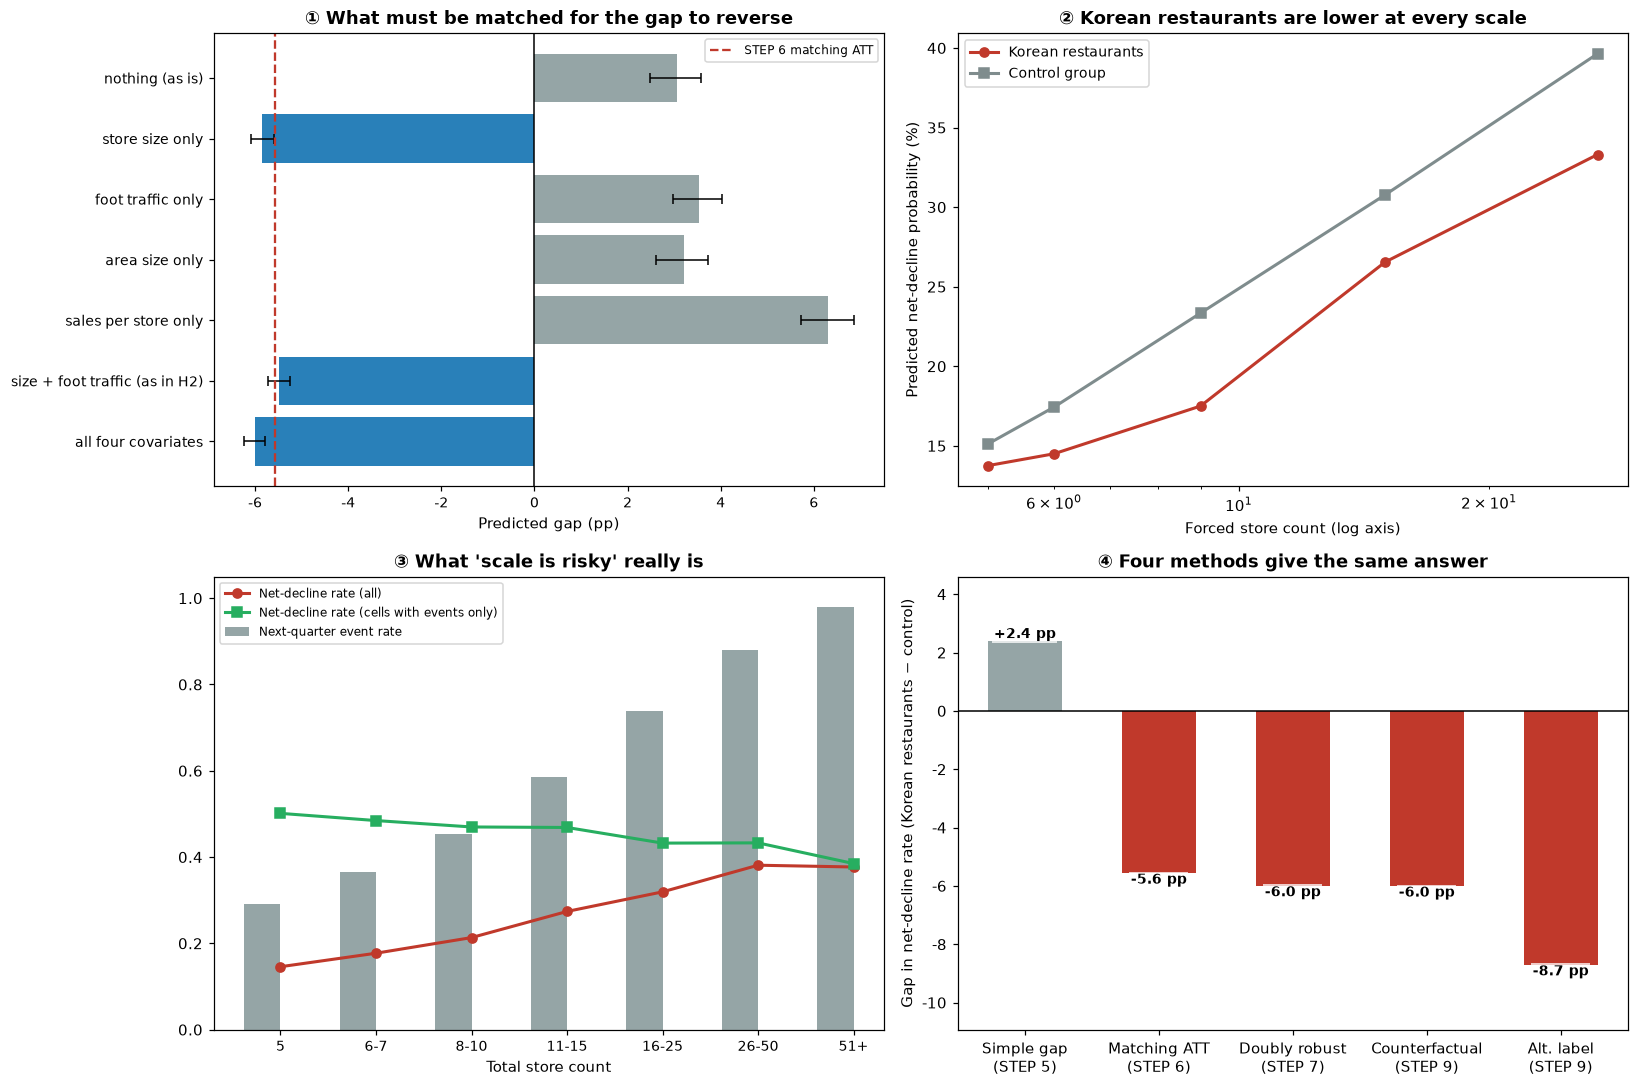

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

# ① Counterfactual
c2 = cf.iloc[::-1]
colors = ["#2980b9" if v < 0 else "#95a5a6" for v in c2["pred_gap"]]
ax[0,0].barh(c2["scenario"], c2["pred_gap"] * 100, color=colors,
             xerr=[(c2["pred_gap"]-c2["CI_low"])*100, (c2["CI_high"]-c2["pred_gap"])*100],
             error_kw=dict(ecolor="k", lw=1, capsize=3))
ax[0,0].axvline(0, c="k", lw=1)
ax[0,0].axvline(ATT6*100, ls="--", c="#c0392b", lw=1.5, label="STEP 6 matching ATT")
ax[0,0].set_xlabel("Predicted gap (pp)"); ax[0,0].tick_params(labelsize=9)
ax[0,0].set_title("① What must be matched for the gap to reverse", weight="bold"); ax[0,0].legend(fontsize=8)

# ② Dose-response
ax[0,1].plot(dose["store_count"], dose[TREAT_SVC]*100, marker="o", lw=2, color="#c0392b", label=TREAT_SVC)
ax[0,1].plot(dose["store_count"], dose["control_group"]*100, marker="s", lw=2, color="#7f8c8d", label="Control group")
ax[0,1].set_xscale("log"); ax[0,1].set_xlabel("Forced store count (log axis)")
ax[0,1].set_ylabel("Predicted net-decline probability (%)")
ax[0,1].set_title("② Korean restaurants are lower at every scale", weight="bold"); ax[0,1].legend(fontsize=9)

# ③ Label arithmetic
x = np.arange(len(tbl)); w = 0.38
ax[1,0].bar(x - w/2, tbl["next_quarter_event_rate"], w, label="Next-quarter event rate", color="#95a5a6")
ax[1,0].plot(x, tbl["net_decline_rate_all"], marker="o", color="#c0392b", lw=2, label="Net-decline rate (all)")
ax[1,0].plot(x, tbl["net_decline_rate_event_cells"], marker="s", color="#27ae60", lw=2,
             label="Net-decline rate (cells with events only)")
ax[1,0].set_xticks(x); ax[1,0].set_xticklabels(tbl.index, fontsize=9)
ax[1,0].set_xlabel("Total store count"); ax[1,0].set_ylim(0, 1.05)
ax[1,0].set_title("③ What 'scale is risky' really is", weight="bold"); ax[1,0].legend(fontsize=8)

# ④ Conclusions converge across methods
labels = ["Simple gap\n(STEP 5)", "Matching ATT\n(STEP 6)", "Doubly robust\n(STEP 7)",
          "Counterfactual\n(STEP 9)", "Alt. label\n(STEP 9)"]
vals = [GAP_RAW, ATT6, ATT_DR,
        float(cf.loc[cf["scenario"] == "all four covariates", "pred_gap"].iloc[0]), att_alt]
cols_ = ["#95a5a6"] + ["#c0392b"]*4
bars = ax[1,1].bar(labels, np.array(vals)*100, color=cols_, width=.55)
ax[1,1].axhline(0, c="k", lw=1); ax[1,1].margins(y=.20)
for b_, v in zip(bars, vals):
    ax[1,1].text(b_.get_x()+b_.get_width()/2, v*100, f"{(v)*100:+.1f} pp".replace("%p", "%p"),
                 ha="center", va="bottom" if v > 0 else "top", weight="bold", fontsize=9,
                 bbox=dict(fc="white", ec="none", alpha=.75, pad=1))
ax[1,1].set_ylabel("Gap in net-decline rate (Korean restaurants − control)")
ax[1,1].set_title("④ Four methods give the same answer", weight="bold")

plt.tight_layout()
plt.savefig(FIG / "step9_conclusion.png", dpi=130)
plt.show()

## 9-6. Saving the conclusions

In [12]:
cf.to_csv(OUT / "h2_counterfactual.csv", index=False, encoding="utf-8-sig")
dose.to_csv(OUT / "h2_dose_response.csv", index=False, encoding="utf-8-sig")
tbl.to_csv(OUT / "q2_label_mechanics.csv", encoding="utf-8-sig")
print("[saved] outputs/h2_counterfactual.csv, h2_dose_response.csv, q2_label_mechanics.csv")
print("[saved] figures/step9_conclusion.png\n")

print("=" * 62)
print("H2 : For service categories with a high net-decline risk in neighborhood commercial areas,")
print("     matching store scale and foot traffic will narrow the gap with other service categories")
print("-" * 62)
print(f"  Simple gap           {(GAP_RAW)*100:+.2f} pp   (Korean restaurants look riskier)")
print(f"  Matching ATT (STEP 6)   {(ATT6)*100:+.2f} pp   sign reversal")
print(f"  Doubly robust (STEP 7)   {(ATT_DR)*100:+.2f} pp")
print(f"  Counterfactual (STEP 9)   {(cf.loc[cf['scenario']=='all four covariates','pred_gap'].iloc[0])*100:+.2f} pp")
print(f"  Alt. label (STEP 9)   {(att_alt)*100:+.2f} pp")
print()
print("  Verdict : partial support — the gap does not 'narrow', it 'reverses'.")
print("         The simple gap was an artifact of scale confounding; once conditions are matched, Korean restaurants are safer.")
print(f"  Refinement : what produces the reversal is store scale alone"
      f" (scale only fixed {(cf.loc[cf['scenario']=='store size only','pred_gap'].iloc[0])*100:+.2f} pp,"
      f" foot traffic only fixed {(cf.loc[cf['scenario']=='foot traffic only','pred_gap'].iloc[0])*100:+.2f} pp).")
print("           Of the two variables H2 named, only one actually works.")
print()
print("=" * 62)
print("Secondary Question 2 : Which characteristics are related to a shift to net decline next quarter")
print("-" * 62)
_eff = pd.read_csv(OUT / "q2_effects.csv", index_col=0)
_svc = pd.read_csv(OUT / "q2_service_effects.csv", index_col=0)
_pi = pd.read_csv(OUT / "pred_perm_importance.csv").set_index("feature")["auc_drop"]
print(f"  1st  Store scale   AME {_eff.loc['log_store_count', 'AME(%p)']:+.1f} pp / permutation importance {_pi['log_store_count']:.3f} — overwhelming")
print("       Note: however, much of it is label arithmetic. Among cells where an event occurred, larger scale is actually lower")
print(f"  2nd  Sales per store  AME  -2.2 pp / permutation {_pi['log_sales_per_store']:.3f} — significant but 1/{_pi['log_store_count'] / _pi['log_sales_per_store']:.0f}")
print(f"  3rd  Foot traffic    AME {_eff.loc['log_foot_traffic', 'AME(%p)']:+.1f} pp (p={_eff.loc['log_foot_traffic', 'p_value']:.3f}) — disappears when store count is controlled (mediation)")
print("       Note: store density is not a separate characteristic — the absolute store count is what works")
_pmax = _svc["p_value"].max()
print(f"  Service category effect : with covariates controlled, Korean restaurants are the safest of the 10 service categories "
      f"(all {len(_svc)} dummies {'+' if (_svc['AME(%p)'] > 0).all() else 'mixed signs'}, "
      f"{'p<0.001' if _pmax < 0.001 else f'max p={_pmax:.4f}'})")
print("  Note: the AME of sales per store (-2.2 pp) is copied from the step7 output (no CSV).")
print("=" * 62)

[saved] outputs/h2_counterfactual.csv, h2_dose_response.csv, q2_label_mechanics.csv
[saved] figures/step9_conclusion.png

H2 : For service categories with a high net-decline risk in neighborhood commercial areas,
     matching store scale and foot traffic will narrow the gap with other service categories
--------------------------------------------------------------
  Simple gap           +2.38 pp   (Korean restaurants look riskier)
  Matching ATT (STEP 6)   -5.57 pp   sign reversal
  Doubly robust (STEP 7)   -6.00 pp
  Counterfactual (STEP 9)   -6.01 pp
  Alt. label (STEP 9)   -8.71 pp

  Verdict : partial support — the gap does not 'narrow', it 'reverses'.
         The simple gap was an artifact of scale confounding; once conditions are matched, Korean restaurants are safer.
  Refinement : what produces the reversal is store scale alone (scale only fixed -5.84 pp, foot traffic only fixed +3.53 pp).
           Of the two variables H2 named, only one actually works.

Secondary Question

---

## What remains

- The **core question** (which service categories shift to net decline, by district) belongs to another team member, so it is not covered here. One thing worth handing over — Section 8-7 of STEP 8. The district x service category level **cannot be validated at all with a single quarter** (split-half reliability of the target value +0.035), and must be evaluated by pooling several quarters
- **H1** was not tested in this pipeline. The commercial-area-type x service category cross-table from STEP 4 remains as descriptive statistics
- Room for improvement — foot traffic by time of day and age group in `01_flow.pkl` is still unused. It may be a better signal than the total for food service